# NMR 反演：恢复弛豫时间分布

这是明确给出参数的物理教学模拟，没有使用实验测量，也不作为模型基准。可修改参数并重新执行，观察结果变化。

In [1]:
import io, json, sys
from pathlib import Path
from IPython.display import display, SVG
root = next(p for p in [Path.cwd(), *Path.cwd().parents] if (p/'openmolspec_bench').is_dir())
sys.path.insert(0, str(root/'src'))
import matplotlib.pyplot as plt
from openmolspec.plotting import figure_style
figure_style()
blue, teal, grey = '#397BA6', '#178F88', '#A8B3BF'


{
  "solver": "scipy.optimize.lsq_linear / BVLS",
  "converged": true,
  "iterations": 6,
  "samples": 100,
  "bins": 100,
  "penalty": "curvature",
  "residual_rmse": 0.0021120632292176774,
  "penalty_norm": 0.049544249842609356,
  "weighted_residual_norm": 0.021120632292176773,
  "kernel_condition_number": 1.4659759173261679e+19,
  "weight_semantics": "discrete bin amplitudes",
  "alpha_selection": "explicit caller value; no automatic GCV claim"
}


/mnt/shared-storage-user/xiejiaqing/OpenMolSpec/studio/.runtime/docs-sphinx/lib/python3.13/site-packages/IPython/core/events.py:101: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  func(*args, **kwargs)


/mnt/shared-storage-user/xiejiaqing/OpenMolSpec/studio/.runtime/docs-sphinx/lib/python3.13/site-packages/IPython/core/pylabtools.py:158: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.canvas.print_figure(bytes_io, **kw)


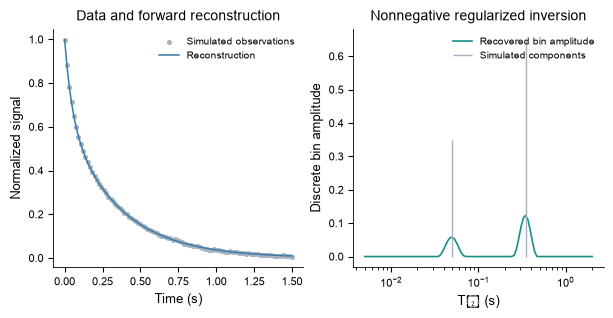

In [2]:
import numpy as np
from openmolspec.inversion import kernel, invert
rng = np.random.default_rng(2026)
time = np.linspace(0, 1.5, 100)
grid = np.geomspace(.005, 2, 100)
truth = np.zeros(100)
locations = [np.argmin(abs(grid-.05)), np.argmin(abs(grid-.35))]
truth[locations] = [.35, .65]
ideal = kernel(time, grid) @ truth
observed = ideal + rng.normal(0,.002,len(time))
result = invert(time, observed, grid, alpha=.01, penalty='curvature')
assert result.diagnostics['converged'] and (result.weights >= 0).all()
assert result.diagnostics['residual_rmse'] < .01
fig, axes = plt.subplots(1, 2, figsize=(7.1, 3.1))
axes[0].scatter(time, observed, color=grey, s=7, label='Simulated observations')
axes[0].plot(time, result.fitted_signal, color=blue, lw=1.1, label='Reconstruction')
axes[0].set(xlabel='Time (s)', ylabel='Normalized signal', title='Data and forward reconstruction')
axes[0].legend(fontsize=7)
axes[1].plot(grid, result.weights, color=teal, lw=1.2, label='Recovered bin amplitude')
axes[1].vlines(grid[locations], 0, truth[locations], color=grey, lw=1, label='Simulated components')
axes[1].set(xscale='log', xlabel='T₂ (s)', ylabel='Discrete bin amplitude', title='Nonnegative regularized inversion')
axes[1].legend(fontsize=7)
print(json.dumps(result.diagnostics, indent=2))

/tmp/ipykernel_1297/2404734664.py:3: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.tight_layout(w_pad=2)


/tmp/ipykernel_1297/2404734664.py:5: UserWarning: Glyph 8322 (\N{SUBSCRIPT TWO}) missing from font(s) Arial.
  fig.savefig(image,format='svg',metadata={'Date':None})


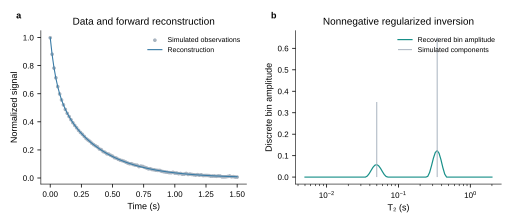

In [3]:
for index, ax in enumerate(axes):
    ax.text(-.12,1.08,chr(97+index),transform=ax.transAxes,fontsize=9,weight='bold')
fig.tight_layout(w_pad=2)
image=io.StringIO()
fig.savefig(image,format='svg',metadata={'Date':None})
display(SVG(image.getvalue()))
plt.close(fig)

[Theory](../theory/index.md) · [Inversion](../inversion/index.md) · [Tutorials](index.md)